In [18]:
import torch

print("torch:", torch.__version__)
print("cuda runtime:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("archs:", torch.cuda.get_arch_list())

if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))

torch: 2.12.0.dev20260319+cu128
cuda runtime: 12.8
cuda available: True
archs: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
gpu: NVIDIA GeForce RTX 5060 Laptop GPU


## 1. Imports

In [19]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report

## 2. Configuration - hyperparameters

In [20]:
DATA_DIR = Path("../data") # change to  data directory location
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
LR = 1e-3
NUM_WORKERS = 4


print("Using device:", DEVICE)

Using device: cuda


## 3. Load dataset

In [21]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
print("train_df shape:", train_df.shape)
print("test_df shape:", test_df.shape) 


# Check for missing files

## List all image files on disk

image_files = list(DATA_DIR.glob("*.jpg"))

print("\nNumber of image files on disk:", len(image_files))

# Use file names (NOT stem!)
actual_files = set(p.name for p in image_files)

## Extract IDs from CSVs

train_ids = set(train_df["image_id"].astype(str))
test_ids = set(test_df["image_id"].astype(str))

all_ids = train_ids | test_ids

print("\nUnique train ids:", len(train_ids))
print("Unique test ids:", len(test_ids))
print("Total unique ids:", len(all_ids))

## Check overlap (should be 0)

overlap = train_ids & test_ids
print("\nOverlap between train/test:", len(overlap))

## Missing images (referenced but not found)

missing_images = all_ids - actual_files

print("\nImages referenced in CSV but missing on disk:", len(missing_images))

## Orphan images (on disk but not referenced)
orphan_images = actual_files - all_ids

print("Images on disk but NOT referenced in CSV:", len(orphan_images))

## Breakdown per dataset

missing_train = train_ids - actual_files
missing_test = test_ids - actual_files

print("\nMissing in train:", len(missing_train))
print("Missing in test:", len(missing_test))






train_df shape: (4800, 2)
test_df shape: (2058, 1)

Number of image files on disk: 6858

Unique train ids: 4800
Unique test ids: 2058
Total unique ids: 6858

Overlap between train/test: 0

Images referenced in CSV but missing on disk: 0
Images on disk but NOT referenced in CSV: 0

Missing in train: 0
Missing in test: 0


In [22]:

# Filter only available images
available_files = set(jpg.name for jpg in DATA_DIR.glob("*.jpg"))

train_df = train_df[train_df["image_id"].isin(available_files)].reset_index(drop=True)
test_df = test_df[test_df["image_id"].isin(available_files)].reset_index(drop=True)

print(train_df.head())
print(len(train_df), "training samples")
print(len(test_df), "test samples")

                                   image_id  ground_truth
0  e7ea0752-f24a-4dac-926c-371fda631a0f.jpg             1
1  cdc7b8e5-1609-4f88-a20d-0dd321f8f489.jpg             0
2  c954e18f-8ab3-4bff-91d7-a0d7ff000e51.jpg             0
3  1c5fb5d5-75e0-431f-a03e-e50026f23fe3.jpg             0
4  fd0dd104-7300-4da3-a46f-6980531ead33.jpg             1
4800 training samples
2058 test samples


## 4. Train / validation split

In [23]:
train_split, val_split = train_test_split(
    train_df,
    test_size=0.2,
    stratify=train_df["ground_truth"],
    random_state=RANDOM_STATE,
)

train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

print("Train split:", len(train_split))
print("Val split:", len(val_split))

Train split: 3840
Val split: 960


## 5. Transforms

In [24]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

## 6. Dataset Class

In [25]:
class EtsyImageDataset(Dataset):
    def __init__(self, df, image_dir, transform=None, is_test=False):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.image_dir / row["image_id"]

        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.is_test:
            return image, row["image_id"]

        label = int(row["ground_truth"])
        return image, label

## 7. Datasets and loaders

In [26]:
train_dataset = EtsyImageDataset(train_split, DATA_DIR, transform=train_transform, is_test=False)
val_dataset = EtsyImageDataset(val_split, DATA_DIR, transform=val_transform, is_test=False)
test_dataset = EtsyImageDataset(test_df, DATA_DIR, transform=val_transform, is_test=True)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

print(len(train_loader), len(val_loader), len(test_loader))

120 30 65


## 8. Model

In [27]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, 2)  # binary classification
model = model.to(DEVICE)

# freeeze all layers except the final fully connected layer
for param in model.parameters():
    param.requires_grad = False 

# unfreeze fc +  4 layers
for param in model.fc.parameters():
    param.requires_grad = True

for param in model.layer4.parameters():
    param.requires_grad = True

## 9. Loss, optimizer, scheduler

In [28]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
)

## 10. Train / validate fucntions

In [29]:
# train
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)

    return epoch_loss, epoch_f1

# validate
def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds)

    return epoch_loss, epoch_f1, all_labels, all_preds

11. Training Loop

In [30]:
NUM_EPOCHS = 10

best_f1 = -1.0
best_model_wts = copy.deepcopy(model.state_dict())
history = []

for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")

    train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_f1, val_labels, val_preds = validate_one_epoch(model, val_loader, criterion, DEVICE)

    scheduler.step(val_f1)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_f1": train_f1,
        "val_loss": val_loss,
        "val_f1": val_f1,
    })

    print(f"Train loss: {train_loss:.4f} | Train F1: {train_f1:.4f}")
    print(f"Val   loss: {val_loss:.4f} | Val   F1: {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(best_model_wts, "best_resnet50.pt")
        print("Saved new best model.")

print("\nBest validation F1:", best_f1)


Epoch 1/10


Train loss: 0.4874 | Train F1: 0.7507
Val   loss: 0.3733 | Val   F1: 0.8298
Saved new best model.

Epoch 2/10


Train loss: 0.2952 | Train F1: 0.8731
Val   loss: 0.3565 | Val   F1: 0.8443
Saved new best model.

Epoch 3/10


Train loss: 0.1967 | Train F1: 0.9217
Val   loss: 0.3538 | Val   F1: 0.8642
Saved new best model.

Epoch 4/10


Train loss: 0.1452 | Train F1: 0.9435
Val   loss: 0.4433 | Val   F1: 0.8306

Epoch 5/10


Train loss: 0.1008 | Train F1: 0.9652
Val   loss: 0.4684 | Val   F1: 0.8378

Epoch 6/10


Train loss: 0.0820 | Train F1: 0.9673
Val   loss: 0.6700 | Val   F1: 0.8322

Epoch 7/10


Train loss: 0.0516 | Train F1: 0.9794
Val   loss: 0.4911 | Val   F1: 0.8611

Epoch 8/10


Train loss: 0.0279 | Train F1: 0.9908
Val   loss: 0.5281 | Val   F1: 0.8481

Epoch 9/10


Train loss: 0.0237 | Train F1: 0.9930
Val   loss: 0.5199 | Val   F1: 0.8642

Epoch 10/10


Train loss: 0.0186 | Train F1: 0.9941
Val   loss: 0.5032 | Val   F1: 0.8693
Saved new best model.

Best validation F1: 0.869287991498406


# 12. Validation performance for best model

In [31]:
model.load_state_dict(torch.load("best_resnet50.pt", map_location=DEVICE))
model.eval()

val_loss, val_f1, val_labels, val_preds = validate_one_epoch(model, val_loader, criterion, DEVICE)

print("Best model validation F1:", val_f1)
print(classification_report(val_labels, val_preds, target_names=["authentic", "ai_generated"]))

Best model validation F1: 0.869287991498406
              precision    recall  f1-score   support

   authentic       0.89      0.86      0.87       497
ai_generated       0.86      0.88      0.87       463

    accuracy                           0.87       960
   macro avg       0.87      0.87      0.87       960
weighted avg       0.87      0.87      0.87       960



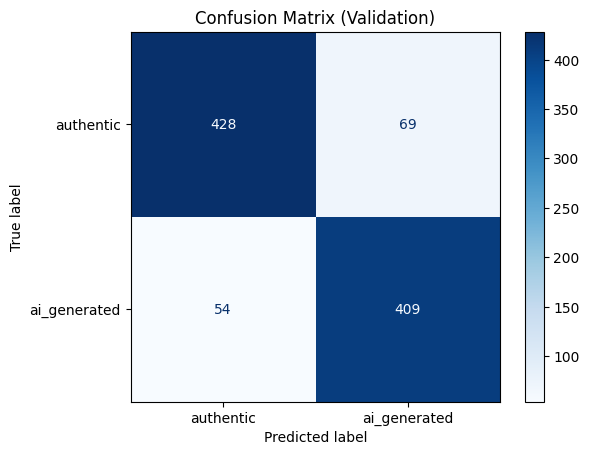

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt
cm = confusion_matrix(val_labels, val_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["authentic", "ai_generated"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix (Validation)")
plt.show()

## 13. History dataframe

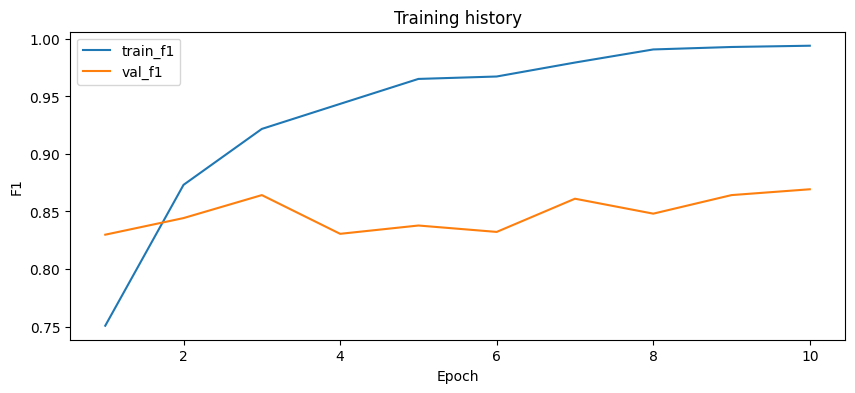

In [33]:
history_df = pd.DataFrame(history)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history_df["epoch"], history_df["train_f1"], label="train_f1")
plt.plot(history_df["epoch"], history_df["val_f1"], label="val_f1")
plt.xlabel("Epoch")
plt.ylabel("F1")
plt.legend()
plt.title("Training history")
plt.show()

## 14. Predict probabilities on test set

In [34]:
def predict_test(model, loader, device):
    model.eval()

    image_ids = []
    probs = []

    with torch.no_grad():
        for images, batch_ids in tqdm(loader, desc="Predicting test"):
            images = images.to(device, non_blocking=True)

            outputs = model(images)
            batch_probs = torch.softmax(outputs, dim=1)[:, 1]  # probability of ai_generated

            probs.extend(batch_probs.cpu().numpy())
            image_ids.extend(batch_ids)

    return pd.DataFrame({
        "image_id": image_ids,
        "ai_generated_proba": probs,
    })



test_pred_df = predict_test(model, test_loader, DEVICE)
test_pred_df.head()

Predicting test: 100%|██████████| 65/65 [00:07<00:00,  8.22it/s]


,image_id,ai_generated_proba
0,3ecf1af5-6a8f-416a-9b4c-df9f2e0a0a80.jpg,0.034141
1,2789b3fe-a337-4dc2-b42c-8bccde1f68fb.jpg,0.000019
2,01a342c6-c3fc-4b55-8c22-13c1a556ba87.jpg,0.000008
3,ac784910-b461-498d-b3a8-50b1e4116b11.jpg,0.009042
4,6dcd4df6-7447-4bcf-a29b-f7f53b4c3ed4.jpg,0.160971


## 15. Convert probabiulities to labels

In [35]:
threshold = 0.6 # can be tuned based on validation set performance

test_pred_df["pred_label_id"] = (test_pred_df["ai_generated_proba"] >= threshold).astype(int)
test_pred_df["ground_truth"] = test_pred_df["pred_label_id"]
# test_pred_df["ground_truth"] = test_pred_df["pred_label_id"].map(id2label)
test_pred_df.head()

,image_id,ai_generated_proba,pred_label_id,ground_truth
0,3ecf1af5-6a8f-416a-9b4c-df9f2e0a0a80.jpg,0.034141,0,0
1,2789b3fe-a337-4dc2-b42c-8bccde1f68fb.jpg,0.000019,0,0
2,01a342c6-c3fc-4b55-8c22-13c1a556ba87.jpg,0.000008,0,0
3,ac784910-b461-498d-b3a8-50b1e4116b11.jpg,0.009042,0,0
4,6dcd4df6-7447-4bcf-a29b-f7f53b4c3ed4.jpg,0.160971,0,0


## 16 Threshold Tuning 

In [36]:
def predict_val_proba(model, loader, device):
    model.eval()

    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Val probabilities", leave=False):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)[:, 1]

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_probs), np.array(all_labels)


val_probs, val_true = predict_val_proba(model, val_loader, DEVICE)

thresholds = np.linspace(0.1, 0.9, 81)
best_thresh = 0.65
best_thresh_f1 = -1

for t in thresholds:
    preds = (val_probs >= t).astype(int)
    f1 = f1_score(val_true, preds)
    if f1 > best_thresh_f1:
        best_thresh_f1 = f1
        best_thresh = t

print("Best threshold:", best_thresh)
print("Best threshold F1:", best_thresh_f1) # to be used for final test predictions

Best threshold: 0.42000000000000004
Best threshold F1: 0.8751311647429171


## 17. Create submission CSV

In [37]:
submission_df = test_pred_df[["image_id", "ground_truth"]].copy()
submission_df.to_csv("submission_resnet50.csv", index=False)

submission_df.head()

,image_id,ground_truth
0,3ecf1af5-6a8f-416a-9b4c-df9f2e0a0a80.jpg,0
1,2789b3fe-a337-4dc2-b42c-8bccde1f68fb.jpg,0
2,01a342c6-c3fc-4b55-8c22-13c1a556ba87.jpg,0
3,ac784910-b461-498d-b3a8-50b1e4116b11.jpg,0
4,6dcd4df6-7447-4bcf-a29b-f7f53b4c3ed4.jpg,0
